<a href="https://colab.research.google.com/github/fran-itu/CienciaCiudades/blob/main/Ciudades.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import CSV

In [3]:
!pip install h3 folium
!pip install h3 folium pandas branca

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 11.8 MB/s  0:00:00


In [4]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import h3
import folium
import branca.colormap as cm


In [5]:
github_raw_url = 'https://raw.githubusercontent.com/fran-itu/CienciaCiudades/main/Escala%20de%20animo(1).csv'

try:
    df = pd.read_csv(github_raw_url, sep=';')
except Exception:
    df = pd.read_csv(github_raw_url, sep=',', on_bad_lines='skip')
display(df.head())

,entryId,userId,uploaded,uploaded_formatted,appType,appVersion,studyId,accessKey,studyVersion,studyLang,...,razonEmocion~other,razonEmocion~other_text,opcionCompañia~4,medidorBateria,medidorBateria~charging,actividadPositiva~3,nivelRuido,nivelRuido~min,nivelRuido~max,cantidadEmociones
0,1000002,drGS-GSCT-9ZC8,1793546748118,2026/11/01 15:25:48,Android,2.22.5,1003,tpecienciasciudadesesmira,1.00,en,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000002,hGg6-NEuM-x2ag,1793550283475,2026/11/01 16:24:43,Android,2.22.2,1003,tpecienciasciudadesesmira,2.10,en,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3000002,dMkL-vGz7-CN2r,1793566303852,2026/11/01 20:51:44,iOS,1.19.3,1003,tpecienciasciudadesesmira,2.28,en,...,NaN,NaN,0.0,10.0,0.0,NaN,NaN,NaN,NaN,NaN
3,2000007,hGg6-NEuM-x2ag,1793621202900,2026/11/02 12:06:43,Android,2.22.2,1003,tpecienciasciudadesesmira,2.10,en,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2000008,hGg6-NEuM-x2ag,1793621202900,2026/11/02 12:06:43,Android,2.22.2,1003,tpecienciasciudadesesmira,2.10,en,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Se borran las variables que no son utiles para el analisis

In [6]:
undone=True
if(undone):
  df = df.iloc[:, 15:]
  cols_to_drop = df.columns[2:8]
  df = df.drop(columns=cols_to_drop)

  undone=False
df = df.dropna(how='all', axis=1)
print(f"New shape: {df.shape}")
display(df.head())

New shape: (129, 46)


,responseTime_formatted,localDateTime,Que esta haciendo ahora,dondeActividad,donde,transporte,transporte~1,transporte~2,transporte~3,transporte~4,...,intensidadAnimo,razonEmocion,opcionCompañia~4,medidorBateria,medidorBateria~charging,actividadPositiva~3,nivelRuido,nivelRuido~min,nivelRuido~max,cantidadEmociones
0,2026/11/01 15:25:47,1/11/2026 12:25 p.m.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026/11/01 16:24:43,1/11/2026 13:24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026/11/01 20:51:43,"1/11/26, 17:51",estudiando,mi casa,NaN,Auto/moto particular,0.0,0.0,1.0,0.0,...,Alta,No,0.0,10.0,0.0,NaN,NaN,NaN,NaN,NaN
3,2026/11/02 12:00:31,2/11/2026 09:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026/11/02 12:01:46,2/11/2026 09:01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df = df.dropna(subset=['Que esta haciendo ahora'])

print(f"New shape after removing null rows: {df.shape}")
display(df.head())

New shape after removing null rows: (124, 46)


,responseTime_formatted,localDateTime,Que esta haciendo ahora,dondeActividad,donde,transporte,transporte~1,transporte~2,transporte~3,transporte~4,...,intensidadAnimo,razonEmocion,opcionCompañia~4,medidorBateria,medidorBateria~charging,actividadPositiva~3,nivelRuido,nivelRuido~min,nivelRuido~max,cantidadEmociones
2,2026/11/01 20:51:43,"1/11/26, 17:51",estudiando,mi casa,NaN,Auto/moto particular,0.0,0.0,1.0,0.0,...,Alta,No,0.0,10.0,0.0,NaN,NaN,NaN,NaN,NaN
5,2026/11/02 12:11:35,2/11/2026 9:11 a.m.,armando mate,casa,89c22b923cbffff,Otro,0.0,0.0,0.0,0.0,...,Alta,Si,0.0,77.0,0.0,0.0,-51.54,-52.94,-50.80,0.0
7,2026/11/02 12:21:06,2/11/2026 09:21,desayunando,casa,89c22b90443ffff,NaN,0.0,0.0,0.0,0.0,...,Baja,No,NaN,94.0,0.0,0.0,-49.86,-62.29,-45.82,1.0
8,2026/11/02 12:04:40,"2/11/26, 09:04",desayunando,mi casa,89c22b9068bffff,Otro,0.0,0.0,0.0,0.0,...,Media,No,0.0,100.0,0.0,NaN,NaN,NaN,NaN,NaN
9,2026/11/02 15:04:18,"2/11/26, 12:04",estudiando,mi casa,89c22b9068bffff,Otro,0.0,0.0,0.0,0.0,...,Alta,No,0.0,55.0,0.0,0.0,-57.45,-71.36,-55.34,1.0


In [8]:

cols_to_drop_zeros = [col for col in df.columns if (df[col] == 0).all()]
df = df.drop(columns=cols_to_drop_zeros)
print(f"Dropped columns: {cols_to_drop_zeros}")
print(f"New shape: {df.shape}")
display(df.head())

Dropped columns: ['medidorBateria~charging']
New shape: (124, 45)


,responseTime_formatted,localDateTime,Que esta haciendo ahora,dondeActividad,donde,transporte,transporte~1,transporte~2,transporte~3,transporte~4,...,valenciaAnimo,intensidadAnimo,razonEmocion,opcionCompañia~4,medidorBateria,actividadPositiva~3,nivelRuido,nivelRuido~min,nivelRuido~max,cantidadEmociones
2,2026/11/01 20:51:43,"1/11/26, 17:51",estudiando,mi casa,NaN,Auto/moto particular,0.0,0.0,1.0,0.0,...,Desagradable,Alta,No,0.0,10.0,NaN,NaN,NaN,NaN,NaN
5,2026/11/02 12:11:35,2/11/2026 9:11 a.m.,armando mate,casa,89c22b923cbffff,Otro,0.0,0.0,0.0,0.0,...,Neutral,Alta,Si,0.0,77.0,0.0,-51.54,-52.94,-50.80,0.0
7,2026/11/02 12:21:06,2/11/2026 09:21,desayunando,casa,89c22b90443ffff,NaN,0.0,0.0,0.0,0.0,...,Agradable,Baja,No,NaN,94.0,0.0,-49.86,-62.29,-45.82,1.0
8,2026/11/02 12:04:40,"2/11/26, 09:04",desayunando,mi casa,89c22b9068bffff,Otro,0.0,0.0,0.0,0.0,...,Neutral,Media,No,0.0,100.0,NaN,NaN,NaN,NaN,NaN
9,2026/11/02 15:04:18,"2/11/26, 12:04",estudiando,mi casa,89c22b9068bffff,Otro,0.0,0.0,0.0,0.0,...,Neutral,Alta,No,0.0,55.0,0.0,-57.45,-71.36,-55.34,1.0


In [9]:

encoded_cols = [col for col in df.columns if re.search(r'\d+$', str(col))]
df = df.drop(columns=encoded_cols)
print(f"Dropped {len(encoded_cols)} encoded columns: {encoded_cols}")
print(f"New shape: {df.shape}")
display(df.head())

Dropped 20 encoded columns: ['transporte~1', 'transporte~2', 'transporte~3', 'transporte~4', 'compañia~1', 'compañia~2', 'opcionCompañia~1', 'opcionCompañia~2', 'opcionCompañia~3', 'compañiaAgradable~1', 'compañiaAgradable~2', 'compañiaAgradable~3', 'esObligatoria~1', 'esObligatoria~2', 'esPlaneada~1', 'esPlaneada~2', 'actividadPositiva~1', 'actividadPositiva~2', 'opcionCompañia~4', 'actividadPositiva~3']
New shape: (124, 25)


,responseTime_formatted,localDateTime,Que esta haciendo ahora,dondeActividad,donde,transporte,transporte~other,transporte~other_text,compañia,opcionCompañia,...,cantidadCompañia,actividadPositiva,valenciaAnimo,intensidadAnimo,razonEmocion,medidorBateria,nivelRuido,nivelRuido~min,nivelRuido~max,cantidadEmociones
2,2026/11/01 20:51:43,"1/11/26, 17:51",estudiando,mi casa,NaN,Auto/moto particular,0.0,NaN,Si,Amigos/as,...,1.0,Si,Desagradable,Alta,No,10.0,NaN,NaN,NaN,NaN
5,2026/11/02 12:11:35,2/11/2026 9:11 a.m.,armando mate,casa,89c22b923cbffff,Otro,1.0,NaN,No,Otro,...,0.0,Neutro,Neutral,Alta,Si,77.0,-51.54,-52.94,-50.80,0.0
7,2026/11/02 12:21:06,2/11/2026 09:21,desayunando,casa,89c22b90443ffff,NaN,0.0,NaN,No,NaN,...,0.0,Si,Agradable,Baja,No,94.0,-49.86,-62.29,-45.82,1.0
8,2026/11/02 12:04:40,"2/11/26, 09:04",desayunando,mi casa,89c22b9068bffff,Otro,1.0,no cambie,No,Otro,...,0.0,Si,Neutral,Media,No,100.0,NaN,NaN,NaN,NaN
9,2026/11/02 15:04:18,"2/11/26, 12:04",estudiando,mi casa,89c22b9068bffff,Otro,1.0,no salí,No,NaN,...,0.0,Si,Neutral,Alta,No,55.0,-57.45,-71.36,-55.34,1.0


# Variables

## Acontecimientos (limpia)

In [10]:
df["cantidadEmociones"].value_counts()

,count
cantidadEmociones,
0.0,106
1.0,16


## Sentimiento e intensidad (limpia)

In [11]:
orden_int = ["Alta", "Media", "Baja"]
orden_val = ["Desagradable", "Neutral", "Agradable"]

grilla = pd.crosstab(df["intensidadAnimo"], df["valenciaAnimo"])
grilla = grilla.reindex(index=orden_int, columns=orden_val)
grilla

valenciaAnimo,Desagradable,Neutral,Agradable
intensidadAnimo,,,
Alta,5,10,3
Media,2,52,25
Baja,0,14,13


In [12]:
etiquetas = {
    ("Alta", "Desagradable"): "Estrés/enojo",
    ("Alta", "Neutral"): "Alerta/sorpresa",
    ("Alta", "Agradable"): "Entusiasmo",
    ("Media", "Desagradable"): "Malestar",
    ("Media", "Neutral"): "Neutro",
    ("Media", "Agradable"): "Contento",
    ("Baja", "Desagradable"): "Tristeza/desánimo",
    ("Baja", "Neutral"): "Calma/aburrimiento",
    ("Baja", "Agradable"): "Relajado/sereno",
}

df["emocion"] = [
    etiquetas.get((i, v)) for i, v in zip(df["intensidadAnimo"], df["valenciaAnimo"])
]
df["emocion"].value_counts()

,count
emocion,
Neutro,52
Contento,25
Calma/aburrimiento,14
Relajado/sereno,13
Alerta/sorpresa,10
Estrés/enojo,5
Entusiasmo,3
Malestar,2


## Que hace (limpia)

In [13]:
df["Que esta haciendo ahora"].value_counts()

,count
Que esta haciendo ahora,
estudiando,22
Estudiando,17
ocio,13
trabajando,7
Desayunando,7
Merendando,6
Cenando,6
Almorzando,4
descanso,3


In [14]:
col = "Que esta haciendo ahora"
df["actividad_norm"] = df[col].str.strip().str.lower()

reglas = [
    ("En movimiento", r"yendo|viajando|volviendo"),
    ("Ocio",          r"ocio|jugando|viendo youtube|con amigos|boludeando"),
    ("Estudio",       r"estudi|cursando|curso|rendir"),
    ("Comiendo",      r"desayunando|almorzando|merendando|cenando|armando mate|cocinando"),
    ("Trabajo",       r"trabajando"),
    ("Descanso",      r"descanso|acostado"),
]

def categorizar(texto):
    for categoria, patron in reglas:
        if re.search(patron, texto):
            return categoria
    return "Otros"

df["categoria"] = df["actividad_norm"].apply(categorizar)

df["categoria"].value_counts()

,count
categoria,
Estudio,45
Comiendo,32
Ocio,24
Trabajo,8
Otros,5
Descanso,5
En movimiento,5


In [15]:
df.loc[df["categoria"] == "Sin clasificar", "actividad_norm"].value_counts()

,count
actividad_norm,


## Donde + ubi (limpia)

In [16]:
df["dondeActividad"].value_counts()

,count
dondeActividad,
Casa,49
casa,36
mi casa,12
colectivo,3
casa abuela,3
Casa amigo,2
Facultad,2
Universidad,2
facultad,2


Todas las casas como casa, universidad/trabajo como lugar de estudio/trabajo  
espacio recreativo y transicion (que hacer con casa amigo)?


In [17]:
col = "dondeActividad"
df["lugar_norm"] = df[col].str.strip().str.lower()

reglas_lugar = [
    ("Casa de otros", r"casa (de )?(abuela|amigo|de mi novio)|casa de mi novio"),
    ("Casa propia",   r"^(mi )?casa$"),
    ("Universidad",   r"universidad|facultad|campus|biblioteca"),
    ("Transporte",    r"colectivo|auto"),
    ("Recreativo",    r"playa|edal|cancha"),
]

def categorizar_lugar(texto):
    for categoria, patron in reglas_lugar:
        if re.search(patron, texto):
            return categoria
    return "Otros"
df["lugar"] = df["lugar_norm"].apply(categorizar_lugar)
df["lugar"].value_counts()

,count
lugar,
Casa propia,97
Universidad,10
Casa de otros,7
Recreativo,5
Transporte,5


In [18]:
df["donde"].value_counts()

,count
donde,
89c22b923cbffff,50
89c2036ed47ffff,21
89c22b90443ffff,14
89c22b9068bffff,12
89c22b9152fffff,7
89c22b9003bffff,2
89c22b9152bffff,2
89c2036766bffff,2
89c2037524bffff,2


## Medio transp (limpia)

In [19]:
df["transporte"].value_counts()

,count
transporte,
Colectivo,26
Auto/moto particular,9
Otro,6
Caminando,2


In [20]:
df.loc[df["transporte"] == "Otro", "transporte~other_text"].value_counts(dropna=False)

,count
transporte~other_text,
NaN,2
no cambie,1
no salí,1
Nada,1
no me moví,1


In [21]:
tiene_texto = df["transporte~other_text"].notna()
df.loc[(df["transporte"] == "Otro") & tiene_texto, "transporte_cat"] = "Sin transporte"
df.loc[(df["transporte"] == "Otro") & ~tiene_texto, "transporte_cat"] = "Sin especificar"
df["transporte_cat"].value_counts()

,count
transporte_cat,
Sin transporte,4
Sin especificar,2


## Razon emocion (limpia)

In [22]:
df['razonEmocion'].value_counts()

,count
razonEmocion,
No,63
Si,61


## Actividad obligatoria,planeada,positiva (limpio)

In [23]:
df['actividadPositiva'].value_counts()

,count
actividadPositiva,
Si,109
Neutro,15


obligatoria y planeada  (labor)  
obligatoria y no planeada  (imprevisto)(emociones negativas)  
no obligatoria y planeada  (ocio)  
no obligatoria y no planeada (sorpresa)(emociones positivas)

In [24]:
# Let's print the relevant columns to see how 'obligatoria' and 'planeada' are structured
relevant_cols = [col for col in df.columns if 'oblig' in col.lower() or 'plan' in col.lower()]
print("Found columns:", relevant_cols)

# Based on the typical structure, we map 'esObligatoria' and 'esPlaneada' to create 'tipoAct'
# Usually these columns contain values like 'Si' / 'No'

def categorize_activity(row):
    # Adjust column names dynamically based on what exists in the DataFrame
    oblig_col = [c for c in relevant_cols if 'oblig' in c.lower()][0]
    plan_col = [c for c in relevant_cols if 'plan' in c.lower()][0]

    is_oblig = str(row[oblig_col]).strip().lower() == 'si'
    is_plan = str(row[plan_col]).strip().lower() == 'si'

    if is_oblig and is_plan:
        return 'labor'
    elif is_oblig and not is_plan:
        return 'imprevisto'
    elif not is_oblig and is_plan:
        return 'ocio'
    else:
        return 'sorpresa'

df['tipoAct'] = df.apply(categorize_activity, axis=1)
print("Value counts for the new 'tipoAct' variable:")
display(df['tipoAct'].value_counts(dropna=False))

Found columns: ['esObligatoria', 'esPlaneada']
Value counts for the new 'tipoAct' variable:


,count
tipoAct,
ocio,61
labor,39
sorpresa,20
imprevisto,4


## % bat (limpia)

In [25]:
df["medidorBateria"].value_counts()

,count
medidorBateria,
63.0,5
69.0,4
77.0,4
35.0,4
50.0,4
...,...
79.0,1
44.0,1
88.0,1


## ruido (limpio con var creada)

In [26]:
# Identify columns containing 'ruido'
ruido_cols = [col for col in df.columns if 'ruido' in col.lower()]
min_col = [col for col in ruido_cols if 'min' in col.lower()][0]
max_col = [col for col in ruido_cols if 'max' in col.lower()][0]
df['ruido_dif'] = df[max_col] - df[min_col]
display(df[[min_col, max_col, 'ruido_dif']].head())

,nivelRuido~min,nivelRuido~max,ruido_dif
2,NaN,NaN,NaN
5,-52.94,-50.80,2.14
7,-62.29,-45.82,16.47
8,NaN,NaN,NaN
9,-71.36,-55.34,16.02


## Compania (limpio)

In [27]:
# Clean values for 'compañia' column to ensure consistency
df['compañia'] = df['compañia'].astype(str).str.strip().str.capitalize()

# Prioritize 'compañia': If 'compañia' is 'No', set 'cantidadCompañia' to 0
df.loc[df['compañia'] == 'No', 'cantidadCompañia'] = 0

# Viceversa: If 'cantidadCompañia' is 0, set 'compañia' to 'No'
df.loc[df['cantidadCompañia'] == 0, 'compañia'] = 'No'

# If 'compañia' is 'No', nullify 'opcionCompañia' and 'compañiaAgradable'
df.loc[df['compañia'] == 'No', ['opcionCompañia', 'compañiaAgradable']] = np.nan

# Verify results
print("Value counts for compañia:")
print(df['compañia'].value_counts(dropna=False))
print("\nValue counts for cantidadCompañia:")
print(df['cantidadCompañia'].value_counts(dropna=False))
print("\nNull counts for opcionCompañia and compañiaAgradable when compañia is 'No':")
print(df[df['compañia'] == 'No'][['opcionCompañia', 'compañiaAgradable']].isna().sum())

Value counts for compañia:
compañia
Si    68
No    56
Name: count, dtype: int64

Value counts for cantidadCompañia:
cantidadCompañia
0.0     56
1.0     52
2.0      8
3.0      3
15.0     2
8.0      1
7.0      1
4.0      1
Name: count, dtype: int64

Null counts for opcionCompañia and compañiaAgradable when compañia is 'No':
opcionCompañia       56
compañiaAgradable    56
dtype: int64


# Tablas

## Actividades positvas: a que se asocian?

In [28]:
con_dato = df[df["actividadPositiva"].notna()]
neutras = df[df["actividadPositiva"] == "Neutro"]
pd.crosstab(con_dato["actividadPositiva"], con_dato["esObligatoria"], normalize="index").round(2)

esObligatoria,No,Si
actividadPositiva,,
Neutro,1.00,0.00
Si,0.61,0.39


In [29]:
pd.crosstab(con_dato["actividadPositiva"], con_dato["esPlaneada"], normalize="index").round(2)

esPlaneada,No,Si
actividadPositiva,,
Neutro,0.47,0.53
Si,0.16,0.84


In [30]:
# Dentro de las neutras
pd.crosstab(neutras["categoria"], neutras["valenciaAnimo"], margins=True)

valenciaAnimo,Agradable,Desagradable,Neutral,All
categoria,,,,
Comiendo,0,0,3,3
Descanso,0,0,2,2
En movimiento,0,1,0,1
Ocio,2,0,7,9
All,2,1,12,15


In [31]:
# Comparación: emoción según si la actividad es neutra o positiva
pd.crosstab(con_dato["actividadPositiva"], con_dato["valenciaAnimo"], margins=True)

valenciaAnimo,Agradable,Desagradable,Neutral,All
actividadPositiva,,,,
Neutro,2,1,12,15
Si,39,6,64,109
All,41,7,76,124


## Emociones: A que se asocian?

In [32]:
orden_val = ["Desagradable", "Neutral", "Agradable"]

def cruce_valencia(df, fila, orden_fila):
    d = df.dropna(subset=[fila, "valenciaAnimo"])
    pct = (pd.crosstab(d[fila], d["valenciaAnimo"], normalize="index") * 100).round(1)
    return pct[orden_val].reindex(orden_fila)

display(cruce_valencia(df, "compañiaAgradable", ["Si", "Neutral"]))
display(cruce_valencia(df, "tipoAct", ["labor", "ocio", "sorpresa", "imprevisto"]))

valenciaAnimo,Desagradable,Neutral,Agradable
compañiaAgradable,,,
Si,2.5,57.5,40.0
Neutral,7.4,70.4,22.2


valenciaAnimo,Desagradable,Neutral,Agradable
tipoAct,,,
labor,12.8,43.6,43.6
ocio,3.3,70.5,26.2
sorpresa,0.0,60.0,40.0
imprevisto,0.0,100.0,0.0


In [33]:
imprevistos = df[df["tipoAct"] == "imprevisto"]

cols = ["localDateTime", "Que esta haciendo ahora", "categoria", "dondeActividad",
        "compañia", "actividadPositiva", "valenciaAnimo", "intensidadAnimo", "nivelRuido"]
cols = [c for c in cols if c in df.columns]

imprevistos[cols]

,localDateTime,Que esta haciendo ahora,categoria,dondeActividad,compañia,actividadPositiva,valenciaAnimo,intensidadAnimo,nivelRuido
8,"2/11/26, 09:04",desayunando,Comiendo,mi casa,No,Si,Neutral,Media,NaN
107,7/11/2026 12:07,estudiando,Estudio,casa,No,Si,Neutral,Media,-57.18
110,8/11/2026 15:02,estudio,Estudio,casa,No,Si,Neutral,Media,-49.24
127,13/11/2026 12:00,estudiando,Estudio,casa,No,Si,Neutral,Baja,-58.82


# Graficas

### Análisis de Nivel de Batería según la Hora del Día
Vamos a analizar cómo se comporta el nivel de batería (`medidorBateria`) del dispositivo a lo largo de las diferentes horas del día (`hora`) para identificar patrones de consumo y recarga.

/tmp/ipykernel_7005/3939353211.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed_dates = pd.to_datetime(df['localDateTime'].str.replace(' ', ' '), errors='coerce')


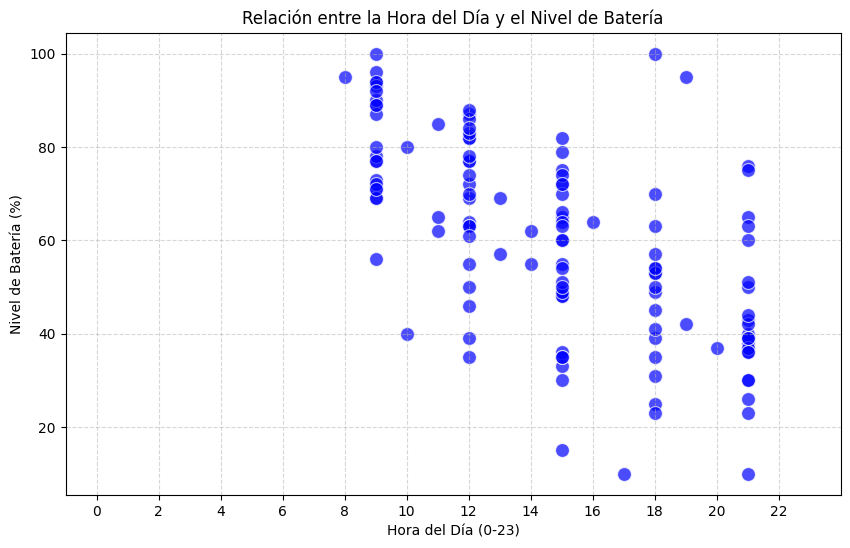

In [34]:
parsed_dates = pd.to_datetime(df['localDateTime'].str.replace(' ', ' '), errors='coerce')
failed_indices = parsed_dates.isna() & df['localDateTime'].notna()
if failed_indices.any():
    # Try custom parsing with format='mixed' if available in this pandas version
    try:
        parsed_dates[failed_indices] = pd.to_datetime(df.loc[failed_indices, 'localDateTime'], format='mixed')
    except Exception:
        pass

df['hora'] = parsed_dates.dt.hour
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='hora', y='medidorBateria', alpha=0.7, color='b', s=100)
plt.title('Relación entre la Hora del Día y el Nivel de Batería')
plt.xlabel('Hora del Día (0-23)')
plt.ylabel('Nivel de Batería (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(-1, 24)
plt.xticks(range(0, 24, 2))
plt.show()

### Análisis de Emociones por Tipo de Actividad
Vamos a comprobar la relación entre los tipos de actividad (`tipoAct`) y si la actividad fue positiva (`actividadPositiva`) mediante una tabla de contingencia y su respectiva visualización.

--- Tabla de Contingencia (Frecuencias Absolutas) ---


valenciaAnimo,Agradable,Desagradable,Neutral,Total
tipoAct,,,,
imprevisto,0,0,4,4
labor,17,5,17,39
ocio,16,2,43,61
sorpresa,8,0,12,20
Total,41,7,76,124



--- Tabla de Porcentajes por Tipo de Actividad (%) ---


valenciaAnimo,Desagradable,Neutral,Agradable
tipoAct,,,
imprevisto,0.00,100.00,0.00
labor,12.82,43.59,43.59
ocio,3.28,70.49,26.23
sorpresa,0.00,60.00,40.00


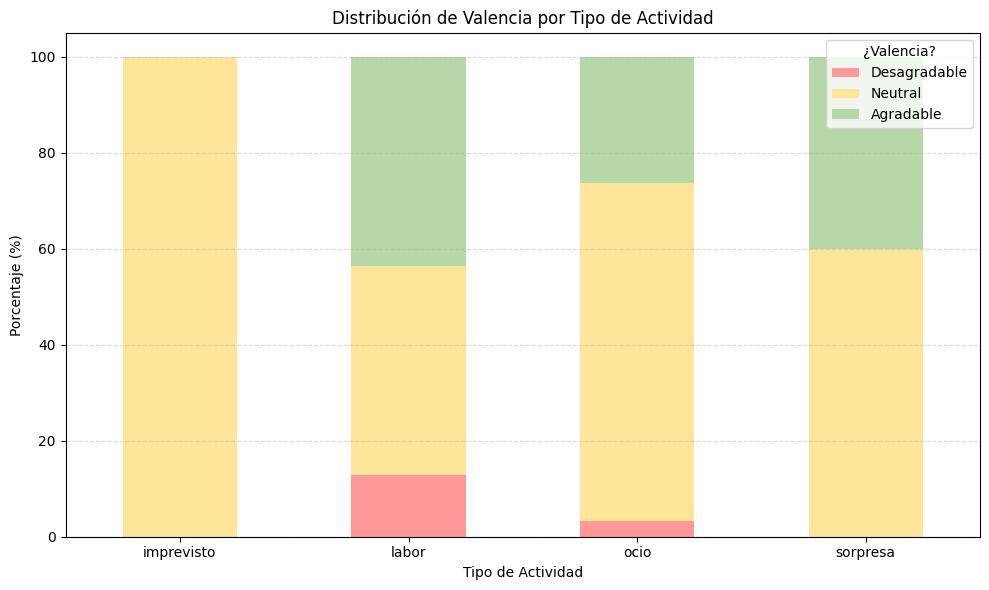

In [35]:
# 1. Crear la tabla de contingencia (frecuencias absolutas y porcentajes)
tabla_contingencia = pd.crosstab(df['tipoAct'], df['valenciaAnimo'], margins=True, margins_name='Total')
tabla_porcentajes = pd.crosstab(df['tipoAct'], df['valenciaAnimo'], normalize='index') * 100

# Reordenar las columnas para asegurar el flujo lógico: Desagradable -> Neutral -> Agradable
column_order = ['Desagradable', 'Neutral', 'Agradable']
# Filtrar solo las columnas que existan en el DataFrame por seguridad
column_order = [col for col in column_order if col in tabla_porcentajes.columns]
tabla_porcentajes = tabla_porcentajes[column_order]

print("--- Tabla de Contingencia (Frecuencias Absolutas) ---")
display(tabla_contingencia)

print("\n--- Tabla de Porcentajes por Tipo de Actividad (%) ---")
display(tabla_porcentajes.round(2))

# 2. Graficar la relación con colores pastel/claros
# Rojo pastel (#ff9999), Amarillo pastel (#fff2cc o #ffe599), Verde pastel (#b6d7a8 o #93c47d)
colores_claros = ['#ff9999', '#ffe599', '#b6d7a8']

plt.figure(figsize=(10, 6))
tabla_porcentajes.plot(kind='bar', stacked=True, color=colores_claros[:len(column_order)], ax=plt.gca())
plt.title('Distribución de Valencia por Tipo de Actividad')
plt.xlabel('Tipo de Actividad')
plt.ylabel('Porcentaje (%)')
plt.legend(title='¿Valencia?')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Análisis de Distribución de Ruido por Hora
Vamos a graficar la diferencia de nivel de ruido (`ruido_dif`) en relación con la hora del día (`hora`) para identificar si existen patrones u horarios más ruidosos. (No usado por que no se permite concluir nada interesante)

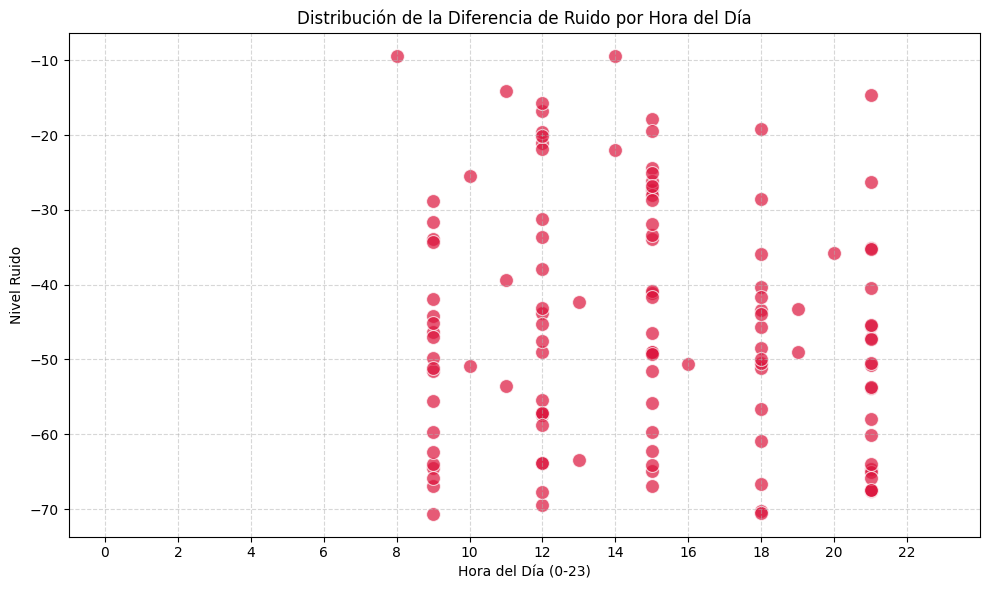

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear el gráfico de dispersión para la diferencia de ruido vs la hora
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='hora', y='nivelRuido', alpha=0.7, color='crimson', s=100)

plt.title('Distribución de la Diferencia de Ruido por Hora del Día')
plt.xlabel('Hora del Día (0-23)')
plt.ylabel('Nivel Ruido')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(-1, 24)
plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

### Comparación de Distribución de Ruido (Min, Promedio, Max)
Vamos a visualizar la distribución de las variables `nivelRuido`, `nivelRuido~min` y `nivelRuido~max` de forma superpuesta usando histogramas con transparencias.

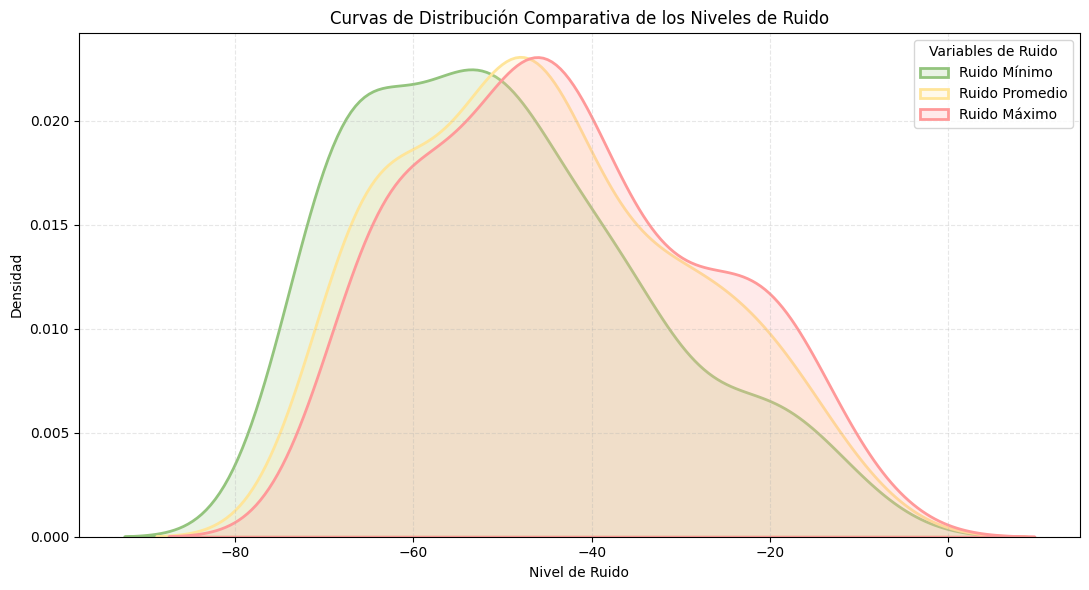

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

# Graficar únicamente las líneas de densidad (KDE) con un relleno muy suave
sns.kdeplot(data=df, x='nivelRuido~min', color='#93c47d', label='Ruido Mínimo', fill=True, alpha=0.2, linewidth=2)
sns.kdeplot(data=df, x='nivelRuido', color='#ffe599', label='Ruido Promedio', fill=True, alpha=0.2, linewidth=2)
sns.kdeplot(data=df, x='nivelRuido~max', color='#ff9999', label='Ruido Máximo', fill=True, alpha=0.2, linewidth=2)

plt.title('Curvas de Distribución Comparativa de los Niveles de Ruido')
plt.xlabel('Nivel de Ruido')
plt.ylabel('Densidad')
plt.legend(title='Variables de Ruido')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis de Relación entre Compañía y Nivel de Ruido
Vamos a comprobar mediante un gráfico de dispersión si el nivel de ruido promedio (`nivelRuido`) se relaciona con la cantidad de acompañantes (`cantidadCompañia`).

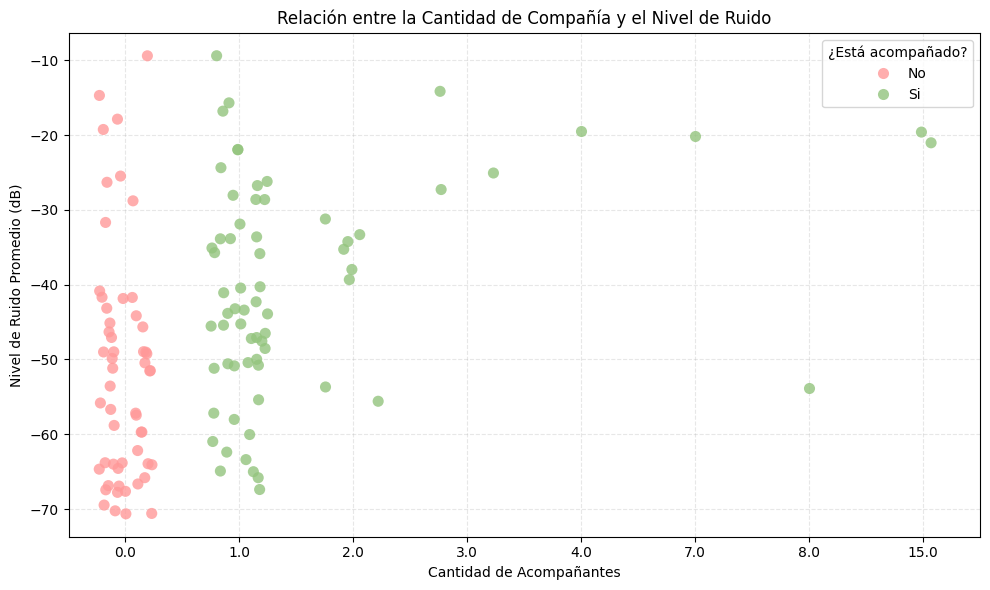

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear el gráfico de dispersión con una leve fluctuación (jitter) para evitar la superposición completa en valores discretos
plt.figure(figsize=(10, 6))
sns.stripplot(
    data=df,
    x='cantidadCompañia',
    y='nivelRuido',
    hue='compañia',
    palette={'Si': '#93c47d', 'No': '#ff9999'},
    jitter=0.25,
    size=8,
    alpha=0.8
)

plt.title('Relación entre la Cantidad de Compañía y el Nivel de Ruido')
plt.xlabel('Cantidad de Acompañantes')
plt.ylabel('Nivel de Ruido Promedio (dB)')
plt.legend(title='¿Está acompañado?')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

### Análisis de Nivel de Ruido según el Lugar
Vamos a comparar la distribución de los niveles de ruido promedio (`nivelRuido`) entre las diferentes categorías de lugares mapeadas (`lugar`) para evaluar qué entornos resultan más ruidosos.

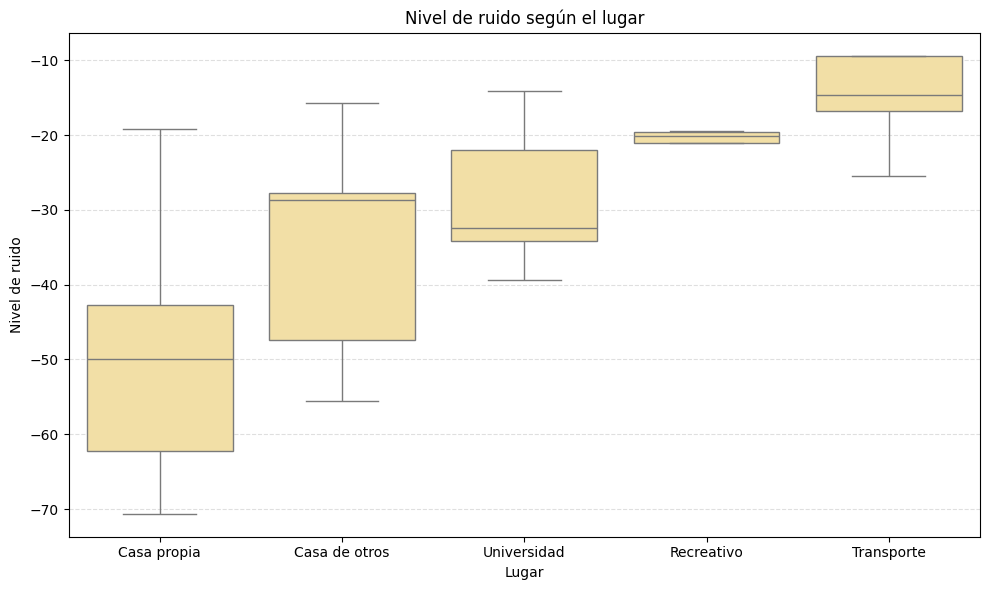

In [39]:
orden = ["Casa propia", "Casa de otros", "Universidad", "Recreativo", "Transporte"]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="lugar", y="nivelRuido", order=orden,
            color="#ffe599", showfliers=False)
plt.title("Nivel de ruido según el lugar")
plt.xlabel("Lugar")
plt.ylabel("Nivel de ruido")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Gráficas de Distribución General (Torta)
Vamos a visualizar la distribución proporcional de las categorías de actividades realizadas, de los estados emocionales reportados y, por último, de aquellas emociones que el usuario identificó con una causa o motivo específico (`razonEmocion` es 'Si').

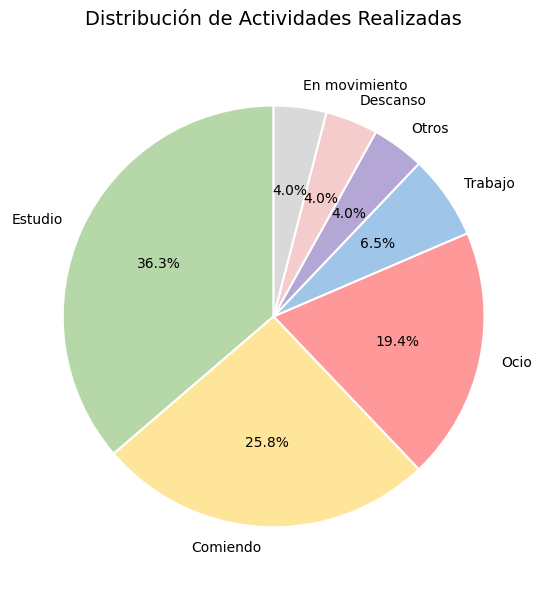

In [44]:
import matplotlib.pyplot as plt

# Paleta de colores consistente con los gráficos anteriores
colores_valencia = ['#ff9999', '#ffe599', '#b6d7a8'] # Desagradable, Neutral, Agradable

# 1. Gráfica de torta para la Categoría de la Actividad
plt.figure(figsize=(8, 6))
cat_counts = df['categoria'].value_counts()
colores_pastel_cat = ['#b6d7a8', '#ffe599', '#ff9999', '#9fc5e8', '#b4a7d6', '#f4cccc', '#d9d9d9']

plt.pie(
    cat_counts,
    labels=cat_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_pastel_cat[:len(cat_counts)],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución de Actividades Realizadas', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

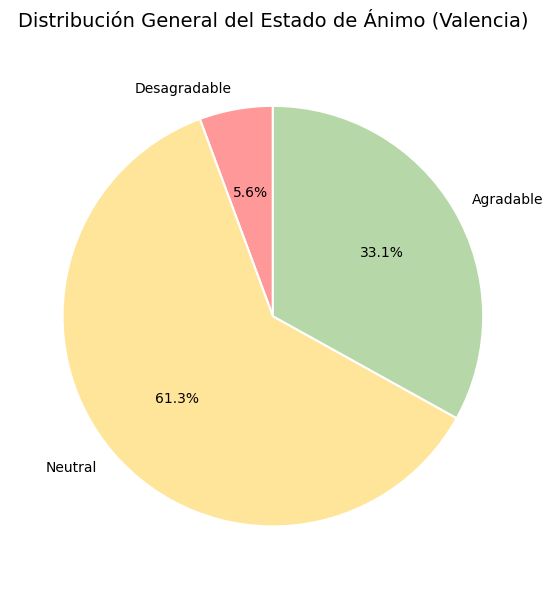

In [45]:
# 2. Gráfica de torta para la Valencia de las Emociones Generales
plt.figure(figsize=(8, 6))
valencia_counts = df['valenciaAnimo'].value_counts()
# Asegurar orden lógico si están presentes
orden_logico = [v for v in ['Desagradable', 'Neutral', 'Agradable'] if v in valencia_counts.index]
valencia_counts = valencia_counts.reindex(orden_logico)

plt.pie(
    valencia_counts,
    labels=valencia_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_valencia[:len(valencia_counts)],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución General del Estado de Ánimo (Valencia)', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

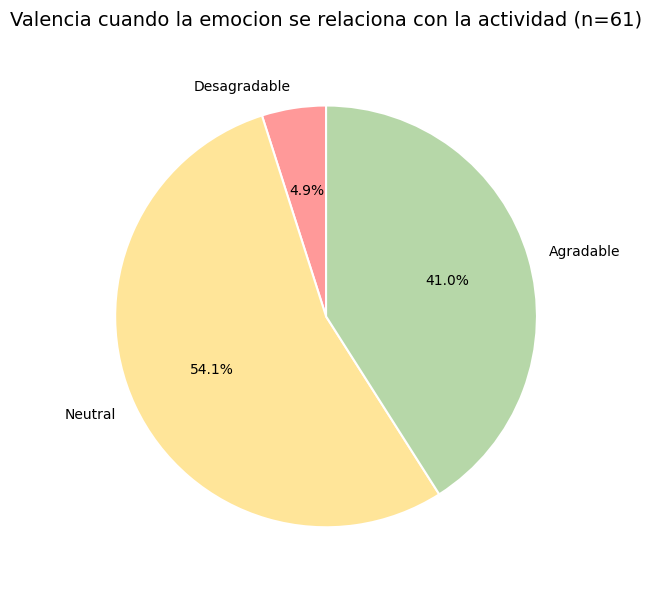

In [48]:
# 3. Gráfica de torta para la Valencia de las Emociones cuando hay un motivo ('razonEmocion' es 'Si')
plt.figure(figsize=(8, 6))
df_razon_si = df[df['razonEmocion'].str.strip().str.capitalize() == 'Si']
valencia_razon_counts = df_razon_si['valenciaAnimo'].value_counts()
orden_logico_razon = [v for v in ['Desagradable', 'Neutral', 'Agradable'] if v in valencia_razon_counts.index]
valencia_razon_counts = valencia_razon_counts.reindex(orden_logico_razon)

plt.pie(
    valencia_razon_counts,
    labels=valencia_razon_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores_valencia[:len(valencia_razon_counts)],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Valencia cuando la emocion se relaciona con la actividad (n=61)', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### Visualización de Mediciones con Celdas H3
Vamos a generar un mapa interactivo utilizando `h3` y `folium` adaptando la lógica de muestras por celda sobre la columna `donde` de nuestro dataset.  
Nota: hay datos en otra ciudad que no fueron llevados al informe para no sobrecargar los mapas, solo se ignoraron en esta seccion.

In [41]:
df_h3 = df[df['donde'].notna() & (df['donde'].astype(str).str.len() == 15)]
conteo = df_h3["donde"].value_counts()

centros = [h3.cell_to_latlng(c) for c in conteo.index]
lat0 = sum(c[0] for c in centros) / len(centros)
lng0 = sum(c[1] for c in centros) / len(centros)

m = folium.Map(location=[lat0, lng0], zoom_start=14, tiles=None)

# Fondo gris claro: deja que los colores resalten
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Gris claro",
).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Calles",
    show=False,
).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Satelital",
    show=False,
).add_to(m)
folium.LayerControl().add_to(m)

# Escala por tramos según percentiles (reparte mejor los colores)
vmin, vmax = int(conteo.min()), int(conteo.max())
cortes = np.unique(np.percentile(conteo.values, [0, 25, 50, 75, 90, 100]))
cortes = sorted(set(cortes.tolist() + [vmin, vmax + 1e-9]))

if len(cortes) >= 3:
    base = cm.linear.YlOrRd_09.scale(vmin, vmax)
    escala = base.to_step(index=cortes)
else:  # casos con casi todos los conteos iguales
    escala = cm.linear.YlOrRd_09.scale(vmin, max(vmax, vmin + 1))
escala.caption = "Muestras por celda H3"

for celda, n in conteo.items():
    folium.Polygon(
        locations=h3.cell_to_boundary(celda),
        color="#222",
        weight=0.8,
        fill=True,
        fill_color=escala(n),
        fill_opacity=0.9,
        tooltip=f"Celda H3: {celda} | {n} muestras",
    ).add_to(m)

escala.add_to(m)

m.save("mapa_muestras.html")
m

Zonas segun actividades

In [42]:
# --- Actividad dominante por celda ---
df_h3 = df[df["donde"].notna() & (df["donde"].astype(str).str.len() == 15)]
tabla = pd.crosstab(df_h3["donde"], df_h3["categoria"])

def dominante(fila):
    fila = fila[fila > 0]
    maximo = fila.max()
    ganadoras = fila[fila == maximo].index.tolist()
    return ganadoras[0] if len(ganadoras) == 1 else "Empate"

dom = tabla.apply(dominante, axis=1)
n_total = tabla.sum(axis=1)

# --- Colores por categoría ---
colores = {
    "Estudio":       "#1f77b4",
    "Comiendo":      "#ff7f0e",
    "Ocio":          "#2ca02c",
    "Trabajo":       "#d62728",
    "Descanso":      "#9467bd",
    "En movimiento": "#17becf",
    "Otros":         "#8c564b",
    "Empate":        "#7f7f7f",
    "Sin dato":      "#cccccc",
}

# --- Mapa base ---
centros = [h3.cell_to_latlng(c) for c in tabla.index]
lat0 = sum(c[0] for c in centros) / len(centros)
lng0 = sum(c[1] for c in centros) / len(centros)

m = folium.Map(location=[lat0, lng0], zoom_start=14, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri", name="Gris claro",
).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri", name="Calles", show=False,
).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri", name="Satelital", show=False,
).add_to(m)
folium.LayerControl().add_to(m)

# --- Celdas ---
for celda in tabla.index:
    fila = tabla.loc[celda]
    detalle = "<br>".join(f"{k}: {v}" for k, v in fila[fila > 0].sort_values(ascending=False).items())
    folium.Polygon(
        locations=h3.cell_to_boundary(celda),
        color="#222",
        weight=0.8,
        fill=True,
        fill_color=colores[dom[celda]],
        fill_opacity=0.85,
        tooltip=folium.Tooltip(f"<b>{dom[celda]}</b> (n = {n_total[celda]})<br>{detalle}"),
    ).add_to(m)

# --- Leyenda ---
usadas = [c for c in colores if c in dom.values]
items = "".join(
    f'<div><span style="background:{colores[c]};width:12px;height:12px;'
    f'display:inline-block;margin-right:6px;border:1px solid #222"></span>{c}</div>'
    for c in usadas
)
leyenda = f"""
<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;
padding:10px 12px;border:1px solid #888;border-radius:6px;font-size:13px;">
<b>Actividad más frecuente</b>{items}</div>
"""
m.get_root().html.add_child(folium.Element(leyenda))

m.save("mapa_actividades.html")
m

Zonas segun emociones

In [43]:
# --- Emoción dominante por celda ---
df_h3 = df[
    df["donde"].notna()
    & (df["donde"].astype(str).str.len() == 15)
    & df["emocion"].notna()
]
tabla = pd.crosstab(df_h3["donde"], df_h3["emocion"])

def dominante(fila):
    fila = fila[fila > 0]
    ganadoras = fila[fila == fila.max()].index.tolist()
    return ganadoras[0] if len(ganadoras) == 1 else "Empate"

dom = tabla.apply(dominante, axis=1)
n_total = tabla.sum(axis=1)

# --- Colores: rojo = desagradable, gris = neutral, verde = agradable ---
colores = {
    "Estrés/enojo":       "#b2182b",
    "Malestar":           "#ef8a62",
    "Tristeza/desánimo":  "#f4a6a6",
    "Alerta/sorpresa":    "#4d4d4d",
    "Neutro":             "#bababa",
    "Calma/aburrimiento": "#e0e0e0",
    "Entusiasmo":         "#1b7837",
    "Contento":           "#7fbf7b",
    "Relajado/sereno":    "#c7e9c0",
    "Empate":             "#fee08b",
}

# --- Mapa base ---
centros = [h3.cell_to_latlng(c) for c in tabla.index]
lat0 = sum(c[0] for c in centros) / len(centros)
lng0 = sum(c[1] for c in centros) / len(centros)

m = folium.Map(location=[lat0, lng0], zoom_start=14, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri", name="Gris claro",
).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri", name="Calles", show=False,
).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri", name="Satelital", show=False,
).add_to(m)
folium.LayerControl().add_to(m)

# --- Celdas ---
for celda in tabla.index:
    fila = tabla.loc[celda]
    detalle = "<br>".join(
        f"{k}: {v}" for k, v in fila[fila > 0].sort_values(ascending=False).items()
    )
    folium.Polygon(
        locations=h3.cell_to_boundary(celda),
        color="#222",
        weight=0.8,
        fill=True,
        fill_color=colores[dom[celda]],
        fill_opacity=0.85,
        tooltip=folium.Tooltip(f"<b>{dom[celda]}</b> (n = {n_total[celda]})<br>{detalle}"),
    ).add_to(m)

# --- Leyenda ---
usadas = [c for c in colores if c in dom.values]
items = "".join(
    f'<div><span style="background:{colores[c]};width:12px;height:12px;'
    f'display:inline-block;margin-right:6px;border:1px solid #222"></span>{c}</div>'
    for c in usadas
)
leyenda = f"""
<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;
padding:10px 12px;border:1px solid #888;border-radius:6px;font-size:13px;">
<b>Emoción más frecuente</b>{items}</div>
"""
m.get_root().html.add_child(folium.Element(leyenda))

m.save("mapa_emociones.html")
m